### Лабораторна робота №2: Групи та підгрупи

**Мета роботи:** Опанувати методи побудови груп в SageMath, дослідити їхню структуру та властивості, навчитися працювати з елементами груп та їхніми підгрупами.

---
### 1. Створюємо групи та досліджуємо їхні властивості

Для кожної з груп: $S_3$, $D_4$, $\mathbb{Z}_{14}$, $\mathbb{Z}_{14}^{*}$, виконайте наступні кроки:
1. Побудуйте групу.
2. Визначте порядок групи.     
3. Знайдіть систему твірних групи.  
4. Виведіть елементи групи.       
5. Виведіть таблицю Келі групи.    
6. Дослідіть, чи є група абелевою. 
7. Виведіть структуру групи.   

In [16]:
def analyze_group(G, name, is_multiplicative=False):
    print(f"Група: {name}")
    elements = list(G)
    print(f"1 і 4. Елементи групи: {elements}")
    order = len(elements)
    print(f"2. Порядок групи: {order}")
    gens = G.gens()
    print(f"3. Система твірних: {gens}")
    print("5. Таблиця:")
    if name == "Z_14":
        print(G.addition_table())
    elif name == "Z_14m":
        print(G.multiplication_table())
    else:
        print(G.cayley_table())
    if name == "Z_14":
        is_ab = True
    else:
        is_ab = G.is_abelian()
    print(f"6. Чи є група абелевою? {is_ab}")
    if name == "Z_14m":
        if G.is_cyclic():
            print("7. Група є циклічною")
        else:
            print("7. Група не є циклічною")
    else:
        if G.is_cyclic():
            print("7. Група є циклічною")
        else:
            print("7. Група не є циклічною")
    print("\n")

S3 = SymmetricGroup(3)
analyze_group(S3, "S_3", is_multiplicative=True)

D4 = DihedralGroup(4)
analyze_group(D4, "D_4", is_multiplicative=True)

Z14 = AdditiveAbelianGroup([14])
analyze_group(Z14, "Z_14")

Z14m = Integers(14).unit_group()
analyze_group(Z14m, "Z_14m", is_multiplicative=True)

Група: S_3
1 і 4. Елементи групи: [(), (1,3,2), (1,2,3), (2,3), (1,3), (1,2)]
2. Порядок групи: 6
3. Система твірних: ((1,2,3), (1,2))
5. Таблиця:
*  a b c d e f
 +------------
a| a b c d e f
b| b a d c f e
c| c e a f b d
d| d f b e a c
e| e c f a d b
f| f d e b c a

6. Чи є група абелевою? False
7. Група не є циклічною


Група: D_4
1 і 4. Елементи групи: [(), (1,3)(2,4), (1,4,3,2), (1,2,3,4), (2,4), (1,3), (1,4)(2,3), (1,2)(3,4)]
2. Порядок групи: 8
3. Система твірних: ((1,2,3,4), (1,4)(2,3))
5. Таблиця:
*  a b c d e f g h
 +----------------
a| a b c d e f g h
b| b a d c f e h g
c| c g a e d h b f
d| d h b f c g a e
e| e f g h a b c d
f| f e h g b a d c
g| g c e a h d f b
h| h d f b g c e a

6. Чи є група абелевою? False
7. Група не є циклічною


Група: Z_14
1 і 4. Елементи групи: [(0), (1), (2), (3), (4), (5), (6), (7), (8), (9), (10), (11), (12), (13)]
2. Порядок групи: 14
3. Система твірних: ((1),)
5. Таблиця:
+  a b c d e f g h i j k l m n
 +----------------------------
a| a b c d

---

### 2. Працюємо з елементами груп

Для кожної з груп: $\mathbb{Z}_{10}$, $\mathbb{Z}_{10}^{*}$, $A_4$, $GL_2(\mathbb{Z}_3)$, виконайте наступні кроки:

1. Побудуйте групу.
2. Виберіть довільні елементи $a, b \in G$ та обчисліть добуток $a \cdot b$.
3. Знайдіть обернені елементи $a^{-1}, b^{-1}$ та виконайте перевірку правильності.
4. Побудуйте підгрупу, породжену елементами $a$ та $b$, і визначте її порядок.
5. Знайдіть всі елементи групи, які є оберненими самі до себе, тобто $a^{-1}=a$.
6. Якщо група $G$ не є абелевою, знайдіть такі елементи $a, b \in G$, що $a \cdot b \neq b \cdot a$.



In [23]:
G = AdditiveAbelianGroup([10])
print("Група:", G)

a = G.gen(0) * 2
b = G.gen(0) * 3
print("a =", a, ", b =", b)
print("Добуток (сума) a + b =", a + b)

print("Обернений a:", -a, " Перевірка:", a + (-a) == G.zero())
print("Обернений b:", -b, " Перевірка:", b + (-b) == G.zero())

H = G.submodule([a, b])
print("Підгрупа H:", H)
print("Порядок підгрупи H:", H.order())

print("Обернені самі до себе:", [x for x in G if -x == x])
print("Чи абелева?:", True)
print("\n")

Група: Additive abelian group isomorphic to Z/10
a = (2) , b = (3)
Добуток (сума) a + b = (5)
Обернений a: (8)  Перевірка: True
Обернений b: (7)  Перевірка: True
Підгрупа H: Additive abelian group isomorphic to Z/10
Порядок підгрупи H: 10
Обернені самі до себе: [(0), (5)]
Чи абелева?: True




In [25]:
R = Integers(10)
G = R.unit_group() 
print("Група:", G)

els = list(G)
a = els[1]
b = els[2]
print("a =", a, ", b =", b)
print("Добуток a * b =", a * b)

print("Обернений a:", a^(-1), "| Перевірка:", a * a^(-1) == G.one())
print("Обернений b:", b^(-1), "| Перевірка:", b * b^(-1) == G.one())

H = G.subgroup([a, b])
print("Підгрупа H:", H)
print("Порядок підгрупи H:", H.order())

print("Обернені самі до себе:", [x for x in G if x^(-1) == x])
print("Чи абелева?:", G.is_abelian())
print("\n")

Група: Multiplicative Abelian group isomorphic to C4
a = f , b = f^2
Добуток a * b = f^3
Обернений a: f^3 | Перевірка: True
Обернений b: f^2 | Перевірка: True
Підгрупа H: Multiplicative Abelian subgroup isomorphic to C4 generated by {f, f^2}
Порядок підгрупи H: 4
Обернені самі до себе: [1, f^2]
Чи абелева?: True




In [26]:
G = AlternatingGroup(4)
print("Група:", G)

a = G.gens()[0]
b = G.gens()[1]
print("a =", a, ", b =", b)
print("Добуток a * b =", a * b)

print("Обернений a:", a^(-1), "| Перевірка:", a * a^(-1) == G.one())
print("Обернений b:", b^(-1), "| Перевірка:", b * b^(-1) == G.one())

H = G.subgroup([a, b])
print("Підгрупа H:", H)
print("Порядок підгрупи H:", H.order())

print("Обернені самі до себе:", [x for x in G if x^(-1) == x])
print("Чи абелева?:", G.is_abelian())
print("Приклад неабелевості (a*b != b*a):")
print("a * b =", a * b)
print("b * a =", b * a)
print("\n")

Група: Alternating group of order 4!/2 as a permutation group
a = (1,2,3) , b = (2,3,4)
Добуток a * b = (1,3)(2,4)
Обернений a: (1,3,2) | Перевірка: True
Обернений b: (2,4,3) | Перевірка: True
Підгрупа H: Subgroup generated by [(1,2,3), (2,3,4)] of (Alternating group of order 4!/2 as a permutation group)
Порядок підгрупи H: 12
Обернені самі до себе: [(), (1,2)(3,4), (1,3)(2,4), (1,4)(2,3)]
Чи абелева?: False
Приклад неабелевості (a*b != b*a):
a * b = (1,3)(2,4)
b * a = (1,2)(3,4)




In [27]:
G = GL(2, 3)
print("Група:", G)

a = G.gens()[0]
b = G.gens()[1]
print("a =", a, ", b =", b)
print("Добуток a * b =", a * b)

print("Обернений a:", a^(-1), "| Перевірка:", a * a^(-1) == G.one())
print("Обернений b:", b^(-1), "| Перевірка:", b * b^(-1) == G.one())

H = G.subgroup([a, b])
print("Підгрупа H:", H)
print("Порядок підгрупи H:", H.order())

print("Обернені самі до себе:", [x for x in G if x^(-1) == x])
print("Чи абелева?:", G.is_abelian())
print("Приклад неабелевості (a*b != b*a):")
print("a * b =", a * b)
print("b * a =", b * a)


Група: General Linear Group of degree 2 over Finite Field of size 3
a = [2 0]
[0 1] , b = [2 1]
[2 0]
Добуток a * b = [1 2]
[2 0]
Обернений a: [2 0]
[0 1] | Перевірка: True
Обернений b: [0 2]
[1 2] | Перевірка: True
Підгрупа H: Subgroup with 2 generators (
[2 0]  [2 1]
[0 1], [2 0]
) of General Linear Group of degree 2 over Finite Field of size 3
Порядок підгрупи H: 48
Обернені самі до себе: [[1 0]
[0 1], [1 1]
[0 2], [2 0]
[0 1], [1 0]
[0 2], [2 2]
[0 1], [2 0]
[0 2], [2 1]
[0 1], [1 0]
[1 2], [0 2]
[2 0], [2 0]
[1 1], [1 0]
[2 2], [0 1]
[1 0], [1 2]
[0 2], [2 0]
[2 1]]
Чи абелева?: False
Приклад неабелевості (a*b != b*a):
a * b = [1 2]
[2 0]
b * a = [1 1]
[1 0]


---
### 3. Підгрупи та їхні властивості

Для кожної з груп $\mathbb{Z}_{24}$, $Q_8$, $D_5$, $S_4$ виконайте наступні кроки:
1. Побудуйте групу.
2. Отримайте та виведіть список усіх підгруп групи.   
3. Визначте кількість підгруп групи з точністю до ізоморфізму.
4. Визначте порядки всіх підгруп групи.
5. Перевірте, чи порядок кожної підгрупи ділить порядок групи.

In [29]:
# 1.
print(" Група Z_24")
G1 = AdditiveAbelianGroup([24])
print("Група:", G1)

gp = G1.permutation_group()
lst = gp.subgroups()
print("Усі підгрупи:")
for n, subgroup in enumerate(lst, start=1):
    print(f"Підгрупа {n}: {subgroup}")

print("Кількість підгруп:", len(set(lst)))

sub_orders = [s.order() for s in lst]
print("Їхні порядки:", sub_orders)

ord_g1 = G1.order()
check_l1 = all(ord_g1 % x == 0 for x in sub_orders)
print("Теорема Лагранжа виконується?:", check_l1)
print("\n")


 Група Z_24
Група: Additive abelian group isomorphic to Z/24
Усі підгрупи:
Підгрупа 1: Subgroup generated by [()] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 2: Subgroup generated by [(4,8)(5,9)(6,10)(7,11)] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 3: Subgroup generated by [(1,2,3)] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 4: Subgroup generated by [(4,6,8,10)(5,7,9,11), (4,8)(5,9)(6,10)(7,11)] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 5: Subgroup generated by [(1,2,3), (4,8)(5,9)(6,10)(7,11)] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 6: Subgroup generated by [(4,5,6,7,8,9,10,11), (4,6,8,10)(5,7,9,11), (4,8)(5,9)(6,10)(7,11)] of (Permutation Group with generators [(1,2,3), (4,5,6,7,8,9,10,11)])
Підгрупа 7: Subgroup generated by [(1,2,3), (4,8)(5,9)(6,10)(7,11), (4,6,8,10)(5,7,9,11)] of (Permutation Group 

In [30]:
print("Група Q_8")
G2 = QuaternionGroup()
print("Група:", G2)

lst2 = G2.subgroups()
print("Усі підгрупи:")
for n, subgroup in enumerate(lst2, start=1):
    print(f"Підгрупа {n}: {subgroup}")

print("Кількість підгруп (ізоморфізм):", len(set(lst2)))

sub_orders2 = [s.order() for s in lst2]
print("Їхні порядки:", sub_orders2)

ord_g2 = G2.order()
check_l2 = all(ord_g2 % x == 0 for x in sub_orders2)
print("Теорема Лагранжа виконується?:", check_l2)
print("\n")

Група Q_8
Група: Quaternion group of order 8 as a permutation group
Усі підгрупи:
Підгрупа 1: Subgroup generated by [()] of (Quaternion group of order 8 as a permutation group)
Підгрупа 2: Subgroup generated by [(1,3)(2,4)(5,7)(6,8)] of (Quaternion group of order 8 as a permutation group)
Підгрупа 3: Subgroup generated by [(1,3)(2,4)(5,7)(6,8), (1,5,3,7)(2,8,4,6)] of (Quaternion group of order 8 as a permutation group)
Підгрупа 4: Subgroup generated by [(1,3)(2,4)(5,7)(6,8), (1,2,3,4)(5,6,7,8)] of (Quaternion group of order 8 as a permutation group)
Підгрупа 5: Subgroup generated by [(1,3)(2,4)(5,7)(6,8), (1,6,3,8)(2,5,4,7)] of (Quaternion group of order 8 as a permutation group)
Підгрупа 6: Subgroup generated by [(1,3)(2,4)(5,7)(6,8), (1,5,3,7)(2,8,4,6), (1,2,3,4)(5,6,7,8)] of (Quaternion group of order 8 as a permutation group)
Кількість підгруп (ізоморфізм): 6
Їхні порядки: [1, 2, 4, 4, 4, 8]
Теорема Лагранжа виконується?: True




In [31]:
print("Група D_5")
G3 = DihedralGroup(5)
print("Група:", G3)

lst3 = G3.subgroups()
print("Усі підгрупи:")
for n, subgroup in enumerate(lst3, start=1):
    print(f"Підгрупа {n}: {subgroup}")

print("Кількість підгруп (ізоморфізм):", len(set(lst3)))

sub_orders3 = [s.order() for s in lst3]
print("Їхні порядки:", sub_orders3)

ord_g3 = G3.order()
check_l3 = all(ord_g3 % x == 0 for x in sub_orders3)
print("Теорема Лагранжа виконується?:", check_l3)
print("\n")

Група D_5
Група: Dihedral group of order 10 as a permutation group
Усі підгрупи:
Підгрупа 1: Subgroup generated by [()] of (Dihedral group of order 10 as a permutation group)
Підгрупа 2: Subgroup generated by [(2,5)(3,4)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 3: Subgroup generated by [(1,2)(3,5)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 4: Subgroup generated by [(1,3)(4,5)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 5: Subgroup generated by [(1,4)(2,3)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 6: Subgroup generated by [(1,5)(2,4)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 7: Subgroup generated by [(1,2,3,4,5)] of (Dihedral group of order 10 as a permutation group)
Підгрупа 8: Subgroup generated by [(1,2,3,4,5), (2,5)(3,4)] of (Dihedral group of order 10 as a permutation group)
Кількість підгруп (ізоморфізм): 8
Їхні порядки: [1, 2, 2, 2, 2, 2, 5, 10]
Теорема Лагранжа викону

In [32]:
print("Група S_4")
G4 = SymmetricGroup(4)
print("Група:", G4)

lst4 = G4.subgroups()
print("Усі підгрупи:")
for n, subgroup in enumerate(lst4, start=1):
    print(f"Підгрупа {n}: {subgroup}")

print("Кількість підгруп (ізоморфізм):", len(set(lst4)))

sub_orders4 = [s.order() for s in lst4]
print("Їхні порядки:", sub_orders4)

ord_g4 = G4.order()
check_l4 = all(ord_g4 % x == 0 for x in sub_orders4)
print("Теорема Лагранжа виконується?:", check_l4)

Група S_4
Група: Symmetric group of order 4! as a permutation group
Усі підгрупи:
Підгрупа 1: Subgroup generated by [()] of (Symmetric group of order 4! as a permutation group)
Підгрупа 2: Subgroup generated by [(1,2)(3,4)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 3: Subgroup generated by [(1,3)(2,4)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 4: Subgroup generated by [(1,4)(2,3)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 5: Subgroup generated by [(3,4)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 6: Subgroup generated by [(2,3)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 7: Subgroup generated by [(2,4)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 8: Subgroup generated by [(1,2)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 9: Subgroup generated by [(1,3)] of (Symmetric group of order 4! as a permutation group)
Підгрупа 10: Subgroup ge

---
### 4. Графи Келі

Графом Келі групи $G$ відносно системи твірних $S$ називається орієнтований граф $\Gamma(G,S)$, вершинами якого є елементи групи і кожний $g\in G$ з'єднаний орієнтованим ребро з $gs$ для всіх $s\in S$.

Для кожної з груп: $D_4$, $Q_8$, $S_3$, $S_4$, $A_4$, виконайте наступні кроки:
1. Побудуйте граф Келі для деякої системи твірних групи.
2. Визначте степінь вершин графа Келі.
3. Перевірте, чи граф Келі є вершинно-транзитивним.
4. Дослідіть, чи граф Келі містить гамільтонів цикл.

1. Побудовано граф Келі для D4


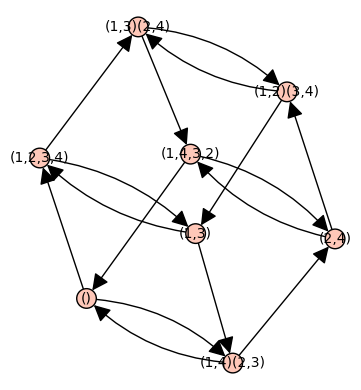

2. Степені вершин графа Келі: [4, 4, 4, 4, 4, 4, 4, 4]
3. Чи є граф вершинно-транзитивним: True
4. Чи містить граф гамільтонів цикл: True




In [45]:
G = DihedralGroup(4)
generators = G.gens()
C = G.cayley_graph(generators=generators)
print("1. Побудовано граф Келі для D4")
C.show()

degrees = C.degree()
print("2. Степені вершин графа Келі:", degrees)

is_vt = C.is_vertex_transitive()
print("3. Чи є граф вершинно-транзитивним:", is_vt)

has_hamiltonian = C.is_hamiltonian()
print("4. Чи містить граф гамільтонів цикл:", has_hamiltonian)
print("\n")

1. Побудовано граф Келі для Q8


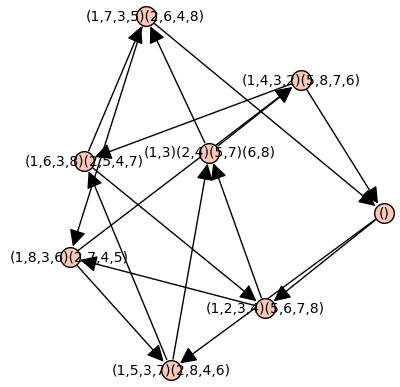

2. Степені вершин графа Келі: [4, 4, 4, 4, 4, 4, 4, 4]
3. Чи є граф вершинно-транзитивним?: True
4. Чи містить граф гамільтонів цикл: True




In [46]:
G = QuaternionGroup()
generators = G.gens()
C = G.cayley_graph(generators=generators)
print("1. Побудовано граф Келі для Q8")
C.show()

degrees = C.degree()
print("2. Степені вершин графа Келі:", degrees)

is_vt = C.is_vertex_transitive()
print("3. Чи є граф вершинно-транзитивним?:", is_vt)

has_hamiltonian = C.is_hamiltonian()
print("4. Чи містить граф гамільтонів цикл:", has_hamiltonian)
print("\n")

1. Побудовано граф Келі для S3


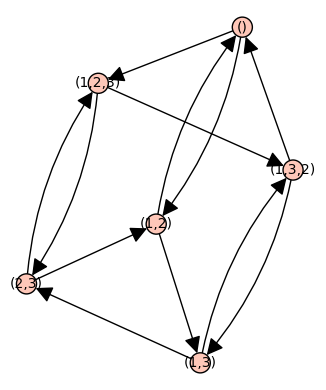

2. Степені вершин графа Келі: [4, 4, 4, 4, 4, 4]
3. Чи є граф вершинно-транзитивним: True
4. Чи містить граф гамільтонів цикл: True




In [47]:
G = SymmetricGroup(3)
generators = G.gens()
C = G.cayley_graph(generators=generators)
print("1. Побудовано граф Келі для S3")
C.show()

degrees = C.degree()
print("2. Степені вершин графа Келі:", degrees)

is_vt = C.is_vertex_transitive()
print("3. Чи є граф вершинно-транзитивним:", is_vt)

has_hamiltonian = C.is_hamiltonian()
print("4. Чи містить граф гамільтонів цикл:", has_hamiltonian)
print("\n")

1. Побудовано граф Келі для S4


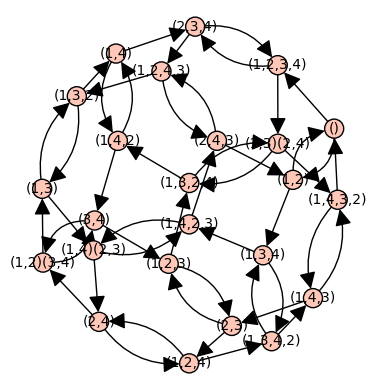

2. Степені вершин графа Келі: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
3. Чи є граф вершинно-транзитивним: True
4. Чи містить граф гамільтонів цикл: False




In [48]:
G = SymmetricGroup(4)
generators = G.gens()
C = G.cayley_graph(generators=generators)
print("1. Побудовано граф Келі для S4")
C.show()

degrees = C.degree()
print("2. Степені вершин графа Келі:", degrees)

is_vt = C.is_vertex_transitive()
print("3. Чи є граф вершинно-транзитивним:", is_vt)

has_hamiltonian = C.is_hamiltonian()
print("4. Чи містить граф гамільтонів цикл:", has_hamiltonian)
print("\n")

1. Побудовано граф Келі для A4


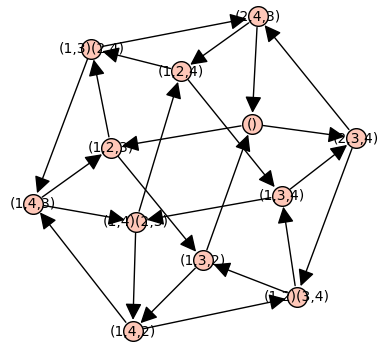

2. Степені вершин графа Келі: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
3. Чи є граф вершинно-транзитивним: True
4. Чи містить граф гамільтонів цикл: False


In [49]:
G = AlternatingGroup(4)
generators = G.gens()
C = G.cayley_graph(generators=generators)
print("1. Побудовано граф Келі для A4")
C.show()

degrees = C.degree()
print("2. Степені вершин графа Келі:", degrees)

is_vt = C.is_vertex_transitive()
print("3. Чи є граф вершинно-транзитивним:", is_vt)

has_hamiltonian = C.is_hamiltonian()
print("4. Чи містить граф гамільтонів цикл:", has_hamiltonian)

---
### 5*. Ймовірність породження симетричної та знакозмінної груп

1. Створіть групу $S_n$ для деякого $n\geq 10$.
2. Проведіть наступний експеримент $m=1000$ разів:<br>
       2.1. Згенеруйте дві випадкові підстановки $a$ та $b$ в $S_n$.<br>
       2.2. Побудуйте групу $H=\langle a,b\rangle$.<br>
       2.3. Перевірте, чи $H$ дорівнює $S_n$, $H=A_n$ або є іншою підгрупою.
3. Обчисліть частоту кожного результату. 
4. Сформулюйте гіпотезу: яка ймовірність породження $S_n$ та $A_n$ двома підстановками.

In [20]:
# Ваш код тут:

---
### 6*. Чи є граф Петерсена графом Келі?

1. Побудуйте граф Петерсена $P$.
2. Побудуйте групу автоморфізмів $G = \text{Aut}(P)$ та знайдіть її порядок.
3. Знайдіть усі підгрупи $H < G$ порядку $10$.
4. Для кожної такої підгрупи $H$ знайдіть усі симетричні системи твірних $S \subset H$ з $|S|=3$.
5. Побудуйте граф Келі $Cay(H, S)$ та перевірте, чи він ізоморфний графу Петерсена $P$.
6. Сформулюйте остаточний висновок.

In [21]:
# Ваш код тут: